## Build a simple trading strategy 

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

### 1. Munging the stock data and add two columns - MA10 and MA50

In [7]:
#import FB's stock data, add two columns - MA10 and MA50
#use dropna to remove any "Not a Number" data
fb = pd.DataFrame.from_csv('../data/facebook.csv')
fb['MA10'] = fb['Close'].rolling(10).mean()
fb['MA50'] = fb['Close'].rolling(50).mean()
fb = fb.dropna()
fb.head()

AttributeError: type object 'DataFrame' has no attribute 'from_csv'

### 2. Add "Shares" column to make decisions base on the strategy 

In [3]:
#Add a new column "Shares", if MA10>MA50, denote as 1 (long one share of stock), otherwise, denote as 0 (do nothing)

fb['Shares'] = [1 if fb.loc[ei, 'MA10']>fb.loc[ei, 'MA50'] else 0 for ei in fb.index]

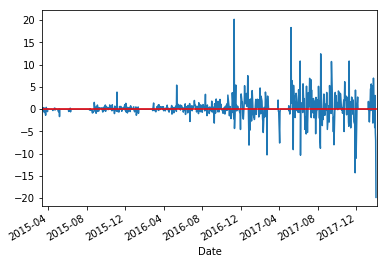

In [4]:
#Add a new column "Profit" using List Comprehension, for any rows in fb, if Shares=1, the profit is calculated as the close price of 
#tomorrow - the close price of today. Otherwise the profit is 0.

#Plot a graph to show the Profit/Loss

fb['Close1'] = fb['Close'].shift(-1)
fb['Profit'] = [fb.loc[ei, 'Close1'] - fb.loc[ei, 'Close'] if fb.loc[ei, 'Shares']==1 else 0 for ei in fb.index]
fb['Profit'].plot()
plt.axhline(y=0, color='red')

### 3. Use .cumsum() to display our model's performance if we follow the strategy 

In [5]:
#Use .cumsum() to calculate the accumulated wealth over the period

fb['wealth'] = fb['Profit'].cumsum()
fb.tail()

,Open,High,Low,Close,Adj Close,Volume,MA10,MA50,Shares,Close1,Profit,wealth
Date,,,,,,,,,,,,
2018-01-30,241.110001,246.419998,238.410004,242.720001,242.720001,14270800,235.692003,210.030001,1,245.800003,3.080002,177.820011
2018-01-31,245.770004,249.270004,244.449997,245.800003,245.800003,11964400,237.800003,210.713801,1,240.500000,-5.300003,172.520008
2018-02-01,238.520004,246.899994,238.059998,240.500000,240.500000,12980600,239.406003,211.296601,1,233.520004,-6.979996,165.540012
2018-02-02,237.000000,237.970001,231.169998,233.520004,233.520004,17961600,239.747003,211.685401,1,213.699997,-19.820007,145.720005
2018-02-05,227.000000,233.229996,205.000000,213.699997,213.699997,28869000,237.748003,211.638401,1,NaN,NaN,NaN


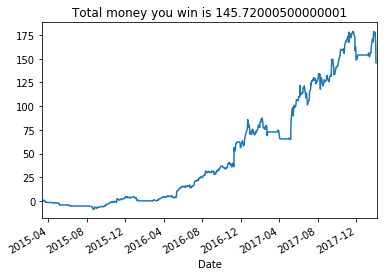

In [6]:
#plot the wealth to show the growth of profit over the period

fb['wealth'].plot()
plt.title('Total money you win is {}'.format(fb.loc[fb.index[-2], 'wealth']))

## You can create your own simple trading strategy by copying the codes above and modify the codes accordingly using the data of Microsoft (microsoft.csv).

In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
%matplotlib inline 

In [4]:
ms=pd.read_csv('../data/microsoft.csv',index_col=0)

FileNotFoundError: [Errno 2] No such file or directory: '../data/microsoft.csv'

In [9]:
ms.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2014-12-31,46.730000,47.439999,46.450001,46.450001,42.848763,21552500
2015-01-02,46.660000,47.419998,46.540001,46.759998,43.134731,27913900
2015-01-05,46.369999,46.730000,46.250000,46.330002,42.738068,39673900
2015-01-06,46.380001,46.750000,45.540001,45.650002,42.110783,36447900
2015-01-07,45.980000,46.459999,45.490002,46.230000,42.645817,29114100


In [11]:
ms.index[0]
ms.index[-1]

'2018-02-05'

In [13]:
ms.shape

(780, 6)

In [14]:
ms.describe

<bound method NDFrame.describe of                  Open       High        Low      Close  Adj Close     Volume
Date                                                                        
2014-12-31  46.730000  47.439999  46.450001  46.450001  42.848763   21552500
2015-01-02  46.660000  47.419998  46.540001  46.759998  43.134731   27913900
2015-01-05  46.369999  46.730000  46.250000  46.330002  42.738068   39673900
2015-01-06  46.380001  46.750000  45.540001  45.650002  42.110783   36447900
2015-01-07  45.980000  46.459999  45.490002  46.230000  42.645817   29114100
2015-01-08  46.750000  47.750000  46.720001  47.590000  43.900375   29645200
2015-01-09  47.610001  47.820000  46.900002  47.189999  43.531395   23942800
2015-01-12  47.419998  47.540001  46.360001  46.599998  42.987129   23651900
2015-01-13  46.970001  47.910000  46.060001  46.360001  42.765747   35270600
2015-01-14  45.959999  46.240002  45.619999  45.959999  42.396751   29719600
2015-01-15  46.220001  46.380001  45.41000

In [18]:
ms['Price1']= ms['Close'].shift(-1)

In [19]:
ms['PriceDiff']= ms['Price1'] - ms['Close']

In [22]:
ms.head()

,Open,High,Low,Close,Adj Close,Volume,Price1,PriceDiff
Date,,,,,,,,
2014-12-31,46.730000,47.439999,46.450001,46.450001,42.848763,21552500,46.759998,0.309997
2015-01-02,46.660000,47.419998,46.540001,46.759998,43.134731,27913900,46.330002,-0.429996
2015-01-05,46.369999,46.730000,46.250000,46.330002,42.738068,39673900,45.650002,-0.680000
2015-01-06,46.380001,46.750000,45.540001,45.650002,42.110783,36447900,46.230000,0.579998
2015-01-07,45.980000,46.459999,45.490002,46.230000,42.645817,29114100,47.590000,1.360000


In [23]:
ms['Return'] = ms['PriceDiff']/ms['Close']

In [38]:
ms['Direction'] = [1 if ms.loc[ei,'PriceDiff']>0 else - 1 for ei in ms.index]

In [30]:
ms['MA10'] = ms['Close'].rolling(10).mean()

In [31]:
ms['MA50'] = ms['Close'].rolling(50).mean()

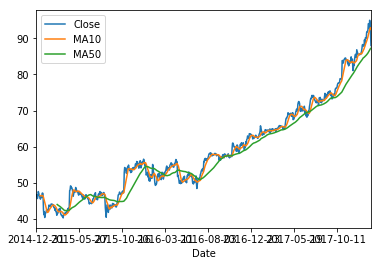

In [32]:
ms['Close'].plot(legend=True)
ms['MA10'].plot(legend=True)
ms['MA50'].plot(legend=True)

In [37]:
ms['Shares']=[1 if ms.loc[ei,'MA10']>ms.loc[ei,'MA50'] else 0 for ei in ms.index]

In [62]:
ms['Profit']=[ms.loc[ei,'Close1']-ms.loc[ei,'Close']if ms.loc[ei,'Shares']==1 else 0 for ei in ms.index]

In [59]:
ms['Close1']= ms['Close'].shift(-1)

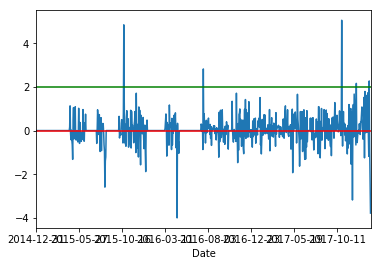

In [69]:
ms['Profit'].plot()
plt.axhline(y=0, color='red')
plt.axhline(y=2, color='green')

In [70]:
ms['wealth']= ms['Profit'].cumsum()

In [71]:
ms.tail()

,Open,High,Low,Close,Adj Close,Volume,Price1,PriceDiff,Return,MA10,MA50,Shares,Direction,Close1,Profit,wealth
Date,,,,,,,,,,,,,,,,
2018-01-30,93.300003,93.660004,92.099998,92.739998,92.306389,38635100,95.010002,2.270004,0.024477,91.862,86.5244,1,1,95.010002,2.270004,30.540009
2018-01-31,93.750000,95.400002,93.510002,95.010002,94.565781,48756300,94.260002,-0.750000,-0.007894,92.349,86.7606,1,-1,94.260002,-0.750000,29.790009
2018-02-01,94.790001,96.070000,93.580002,94.260002,93.819290,47227900,91.779999,-2.480003,-0.026310,92.765,86.9978,1,-1,91.779999,-2.480003,27.310006
2018-02-02,93.639999,93.970001,91.500000,91.779999,91.350883,47867800,88.000000,-3.779999,-0.041185,92.943,87.1828,1,-1,88.000000,-3.779999,23.530007
2018-02-05,90.559998,93.239998,88.000000,88.000000,87.588554,51031500,NaN,NaN,NaN,92.582,87.2684,1,-1,NaN,NaN,NaN


In [1]:
ms['Wealth'].plot()
plt.title('Total money you win is{}'.format(ms.loc[ms.index[-2],'Wealth']))

NameError: name 'ms' is not defined

In [85]:
ms.head()

,Open,High,Low,Close,Adj Close,Volume,Price1,PriceDiff,Return,MA10,MA50,Shares,Direction,Close1,Profit,wealth
Date,,,,,,,,,,,,,,,,
2014-12-31,46.730000,47.439999,46.450001,46.450001,42.848763,21552500,46.759998,0.309997,0.006674,NaN,NaN,0,1,46.759998,0.0,0.0
2015-01-02,46.660000,47.419998,46.540001,46.759998,43.134731,27913900,46.330002,-0.429996,-0.009196,NaN,NaN,0,-1,46.330002,0.0,0.0
2015-01-05,46.369999,46.730000,46.250000,46.330002,42.738068,39673900,45.650002,-0.680000,-0.014677,NaN,NaN,0,-1,45.650002,0.0,0.0
2015-01-06,46.380001,46.750000,45.540001,45.650002,42.110783,36447900,46.230000,0.579998,0.012705,NaN,NaN,0,1,46.230000,0.0,0.0
2015-01-07,45.980000,46.459999,45.490002,46.230000,42.645817,29114100,47.590000,1.360000,0.029418,NaN,NaN,0,1,47.590000,0.0,0.0
